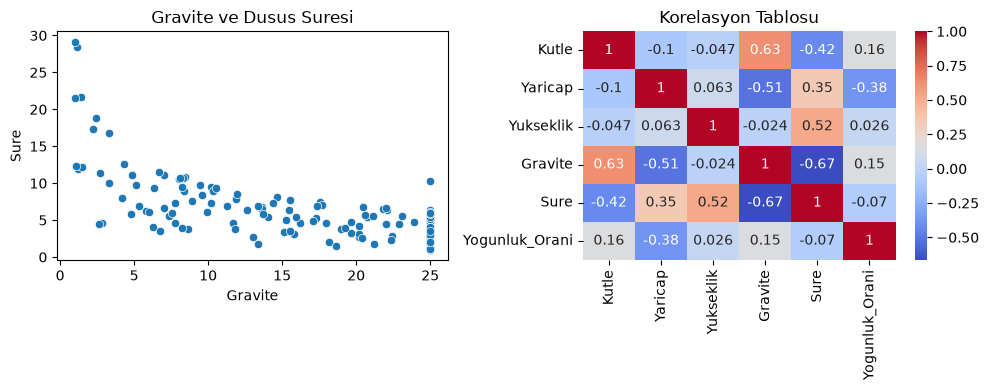

Linear Regression Hata (MAE): 3.66
Random Forest Hata (MAE): 1.1
Random Forest Basari (R2): 0.81


In [ ]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

def veri_olustur():
    np.random.seed(42)
    n = 300
    G = 6.674e-11
    kutle = np.random.uniform(1e22, 2e27, n)
    yaricap = np.random.uniform(1e6, 7e7, n)
    yukseklik = np.random.uniform(10, 500, n)

    gravite = np.clip((G * kutle) / (yaricap ** 2), 1.0, 25.0)
    sure = np.sqrt((2 * yukseklik) / gravite)

    df = pd.DataFrame({
        "Kutle": np.round(kutle / 1e24, 2),
        "Yaricap": np.round(yaricap / 1000, 1),
        "Yukseklik": np.round(yukseklik, 1),
        "Gravite": np.round(gravite, 2),
        "Sure": np.round(sure, 2)
    })
    df.loc[0:5, "Gravite"] = np.nan  # Eksik veri örneği

    baglanti = sqlite3.connect("gravite.db")
    df.to_sql("olcumler", baglanti, if_exists="replace", index=False)
    veri = pd.read_sql_query("SELECT * FROM olcumler", baglanti)
    baglanti.close()
    return veri

def veri_temizle(df):
    df["Gravite"] = df["Gravite"].fillna(df["Gravite"].median())
    df["Yogunluk_Orani"] = df["Kutle"] / (df["Yaricap"] ** 2)
    return df


def grafik_ciz(df):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    sns.scatterplot(data=df, x="Gravite", y="Sure", ax=ax[0]).set_title("Gravite ve Dusus Suresi")
    sns.heatmap(df.corr(), annot=True, cmap="coolwarm", ax=ax[1]).set_title("Korelasyon Tablosu")
    plt.tight_layout()
    plt.savefig("gravite_grafik.png")
    plt.show()


def model_kur(df):
    X = df[["Kutle", "Yaricap", "Yukseklik", "Yogunluk_Orani"]]
    y = df["Gravite"]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    lr = LinearRegression()
    lr.fit(X_train, y_train)
    tahmin_lr = lr.predict(X_test)

    rf = RandomForestRegressor(n_estimators=50, random_state=42)
    rf.fit(X_train, y_train)
    tahmin_rf = rf.predict(X_test)

    print("Linear Regression Hata (MAE):", round(mean_absolute_error(y_test, tahmin_lr), 2))
    print("Random Forest Hata (MAE):", round(mean_absolute_error(y_test, tahmin_rf), 2))
    print("Random Forest Basari (R2):", round(r2_score(y_test, tahmin_rf), 2))


df = veri_olustur()
df = veri_temizle(df)
grafik_ciz(df)
model_kur(df)
